# 04 - Final Model

In [1]:
import sys
!{sys.executable} -m pip install optuna xgboost lightgbm shap imbalanced-learn scikit-learn pandas numpy matplotlib seaborn joblib

In [2]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import warnings
warnings.filterwarnings('ignore')

import config as cfg
from src.preprocess          import load_and_prepare, scale
from src.feature_engineering import engineer_features
from src.preprocess          import split_engineered
from src.train               import (train_xgb, tune_xgb_optuna,
                                     tune_threshold, save_model, load_model)
from src.evaluate            import (get_metrics, plot_cm, plot_roc,
                                     plot_threshold_curve,
                                     plot_shap_summary, plot_shap_waterfall,
                                     comparison_table, print_report)

print('All imports OK')

All imports OK


In [3]:
data = load_and_prepare()
df   = data['df']
spw  = data['spw']

df_eng = engineer_features(df)
X_train_e, X_val_e, X_test_e, y_train_e, y_val_e, y_test_e = \
    split_engineered(df_eng)

print(f'Feature count : {len(cfg.ALL_FEATURES)}')
print(f'Train rows    : {len(X_train_e):,}')

[load_raw] Loaded 101,371 rows × 16 cols
[clean] Dropped 5,062 pre-season rows → 96,309 remain
[clean] Filled 66 nulls in Compound with 'UNKNOWN'
[encode] Added OHE columns: ['C_HARD', 'C_INTERMEDIATE', 'C_MEDIUM', 'C_SOFT', 'C_UNKNOWN', 'C_WET']
[encode] Added Driver_Freq, Compound_Ordinal
[split] Train  :  44,117 rows  | pit rate = 0.157
[split] Val    :  26,381 rows  | pit rate = 0.343
[split] Test   :  25,811 rows  | pit rate = 0.332
[class_weight] neg=37,178 pos=6,939 → scale_pos_weight=5.358
[engineer_features] Added 7 features: ['LapTime_Roll3', 'LapTime_Accel', 'LapsSinceLastPit', 'RacePhase', 'TyreLife_x_Compound', 'Position_Roll3', 'DegRate_Roll3']
[split_eng] Train  :  44,117 | Val: 26,381 | Test: 25,811
Feature count : 25
Train rows    : 44,117


In [4]:
#HyperParameter Tuning-Optuna
# Set n_trials=20 for a quick run; 50 for submission quality
best_params, best_val = tune_xgb_optuna(
    X_train_e, y_train_e,
    X_val_e,   y_val_e,
    spw=spw, n_trials=50
)
print(f'\nBest val F1: {best_val:.4f}')
print(json.dumps(best_params, indent=2))

  0%|          | 0/50 [00:00<?, ?it/s]

[tune_xgb_optuna] Best val F1=0.6735
[tune_xgb_optuna] Best params: {'n_estimators': 505, 'max_depth': 6, 'learning_rate': 0.03707990099213827, 'subsample': 0.5194867127598993, 'colsample_bytree': 0.9914581574783385, 'min_child_weight': 1, 'gamma': 2.351875767134867, 'scale_pos_weight': np.float64(5.357832540711918), 'eval_metric': 'aucpr', 'random_state': 42, 'n_jobs': -1, 'verbosity': 0}

Best val F1: 0.6735
{
  "n_estimators": 505,
  "max_depth": 6,
  "learning_rate": 0.03707990099213827,
  "subsample": 0.5194867127598993,
  "colsample_bytree": 0.9914581574783385,
  "min_child_weight": 1,
  "gamma": 2.351875767134867,
  "scale_pos_weight": 5.357832540711918,
  "eval_metric": "aucpr",
  "random_state": 42,
  "n_jobs": -1,
  "verbosity": 0
}


In [5]:
#Final Model Train
final_model = train_xgb(
    X_train_e, y_train_e,
    X_val_e,   y_val_e,
    spw=spw, **{k: v for k, v in best_params.items()
               if k not in ('scale_pos_weight', 'eval_metric',
                             'random_state', 'n_jobs', 'verbosity')}
)

[train_xgb] XGBoost fitted. n_estimators=505


## 4. Threshold tuning for final model

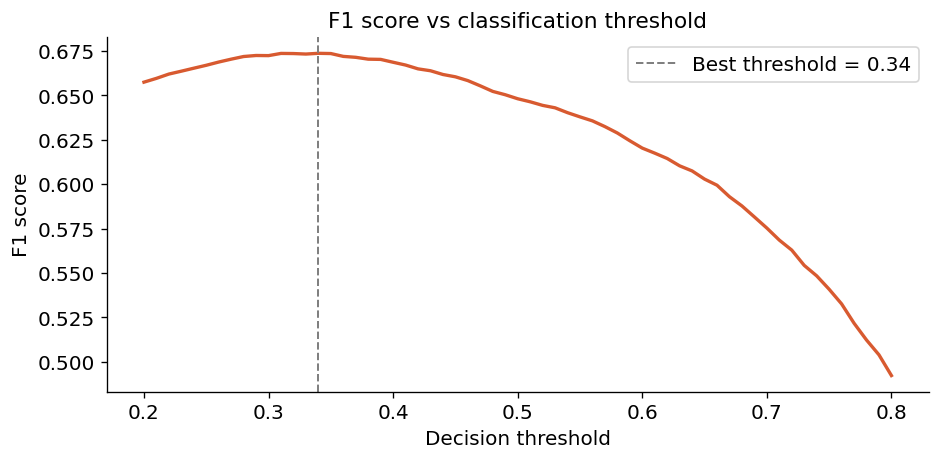

Final threshold: 0.34000000000000014
Model        XGBoost (tuned)
Accuracy              0.7312
Precision             0.5775
Recall                0.8082
F1                    0.6737
ROC-AUC               0.8186
dtype: object


In [6]:
#Final Model-Threshold Tuning
final_thresh = plot_threshold_curve(final_model, X_val_e, y_val_e)
print(f'Final threshold: {final_thresh}')

final_probs = final_model.predict_proba(X_val_e)[:, 1]
final_preds = (final_probs >= final_thresh).astype(int)

final_results = get_metrics(
    'XGBoost (tuned)', y_val_e, final_preds, final_probs
)
print(pd.Series(final_results))


  XGBoost (tuned) — Classification Report
              precision    recall  f1-score   support

      No Pit       0.87      0.69      0.77     17326
         Pit       0.58      0.81      0.67      9055

    accuracy                           0.73     26381
   macro avg       0.73      0.75      0.72     26381
weighted avg       0.77      0.73      0.74     26381



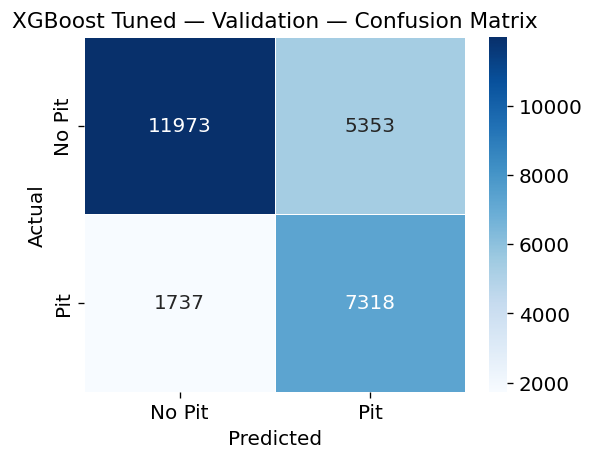

In [7]:
print_report('XGBoost (tuned)', y_val_e, final_preds)
plot_cm(y_val_e, final_preds, 'XGBoost Tuned — Validation',
        fname='final_val_cm.png')

In [8]:
# Load earlier results
try:
    lr_res  = json.loads((cfg.OUT_DIR / 'lr_results.json').read_text())
except:
    lr_res  = {'Model': 'LR (run nb02)', 'F1': 0, 'ROC-AUC': 0,
                'Accuracy': 0, 'Precision': 0, 'Recall': 0}

# XGB base and eng from nb03
xgb_base = load_model('xgb_base')
xgb_eng  = load_model('xgb_eng')
thresh_info = json.loads((cfg.OUT_DIR / 'xgb_eng_thresh.json').read_text())
eng_thresh  = thresh_info['threshold']

xgb_base_probs = xgb_base.predict_proba(X_val_e[cfg.BASE_FEATURES])[:, 1]
xgb_base_preds = (xgb_base_probs >= 0.5).astype(int)
xgb_eng_probs  = xgb_eng.predict_proba(X_val_e)[:, 1]
xgb_eng_preds  = (xgb_eng_probs >= eng_thresh).astype(int)

xgb_base_res = get_metrics('XGBoost (base)', y_val_e, xgb_base_preds, xgb_base_probs)
xgb_eng_res  = get_metrics('XGBoost + Eng', y_val_e, xgb_eng_preds, xgb_eng_probs)

all_results = comparison_table([lr_res, xgb_base_res, xgb_eng_res, final_results])

[load_model] Loaded ← c:\Users\adity\OneDrive\Desktop\F1-Pitstop-Predictor\notebooks\..\outputs\models\xgb_base.joblib
[load_model] Loaded ← c:\Users\adity\OneDrive\Desktop\F1-Pitstop-Predictor\notebooks\..\outputs\models\xgb_eng.joblib

Results saved → c:\Users\adity\OneDrive\Desktop\F1-Pitstop-Predictor\notebooks\..\outputs\results_summary.csv
                      Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                             
LR + tuned threshold    0.6125     0.4617  0.7764  0.5790   0.7128
XGBoost (base)          0.7385     0.5989  0.7208  0.6542   0.8160
XGBoost + Eng           0.7243     0.5681  0.8204  0.6714   0.8187
XGBoost (tuned)         0.7312     0.5775  0.8082  0.6737   0.8186


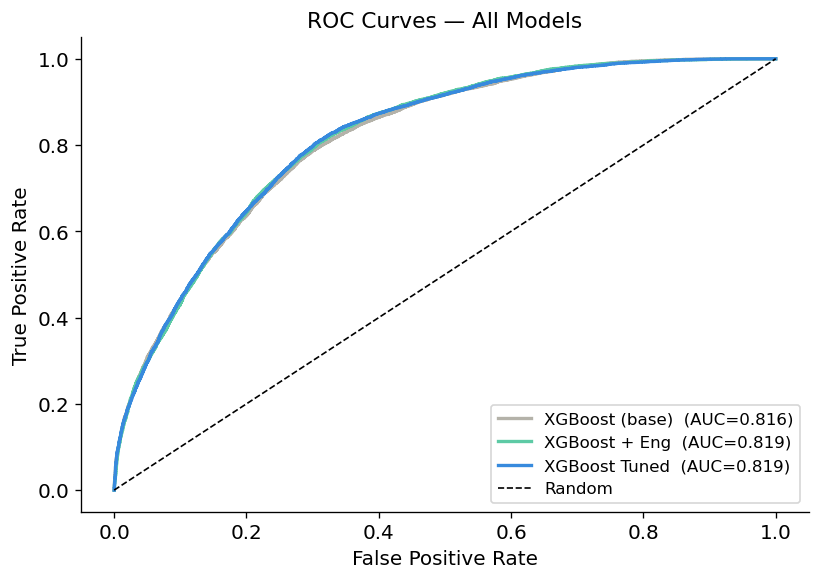

In [9]:
# ROC overlay
plot_roc([
    ('XGBoost (base)', xgb_base_probs),
    ('XGBoost + Eng',  xgb_eng_probs),
    ('XGBoost Tuned',  final_probs),
], y_val_e)

##  SHAP - Model Interpretation

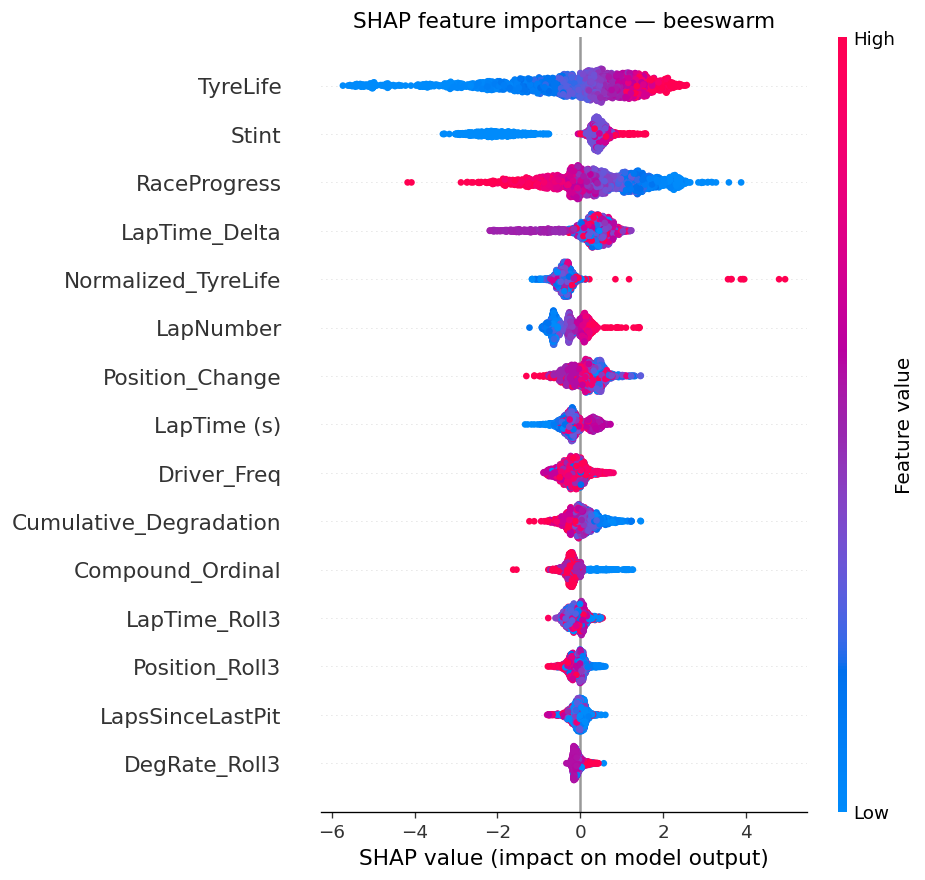

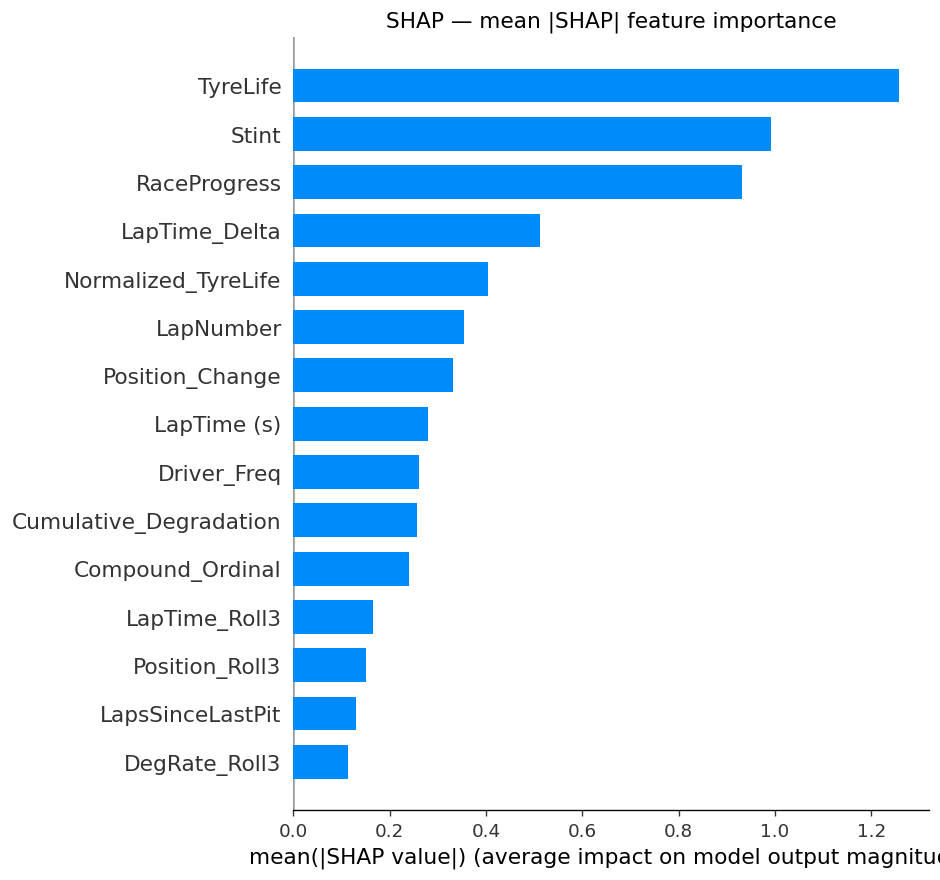

In [10]:
# Use a 2000-row sample for speed
np.random.seed(42)
idx = np.random.choice(len(X_val_e), size=2000, replace=False)
X_sample = X_val_e.iloc[idx]

shap_vals = plot_shap_summary(final_model, X_sample, cfg.ALL_FEATURES)

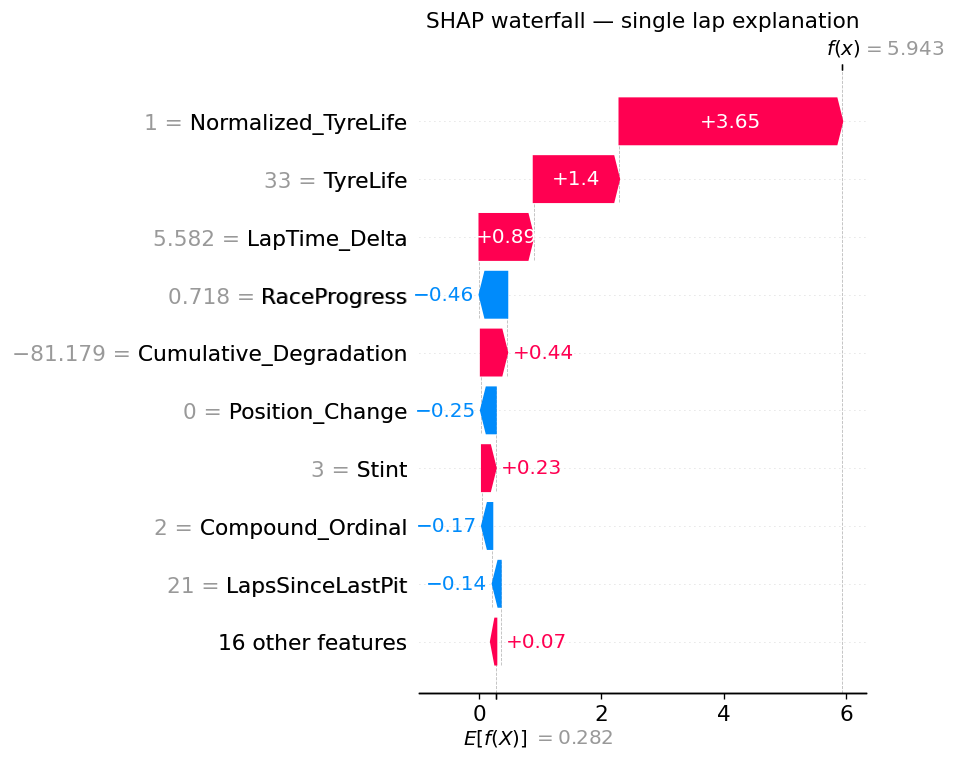

In [11]:
# Waterfall - explain one individual prediction
# Pick the row with highest predicted probability (confident pit prediction)
confident_pit_idx = np.argmax(final_probs[idx])
plot_shap_waterfall(final_model, X_sample, cfg.ALL_FEATURES,
                    idx=confident_pit_idx)

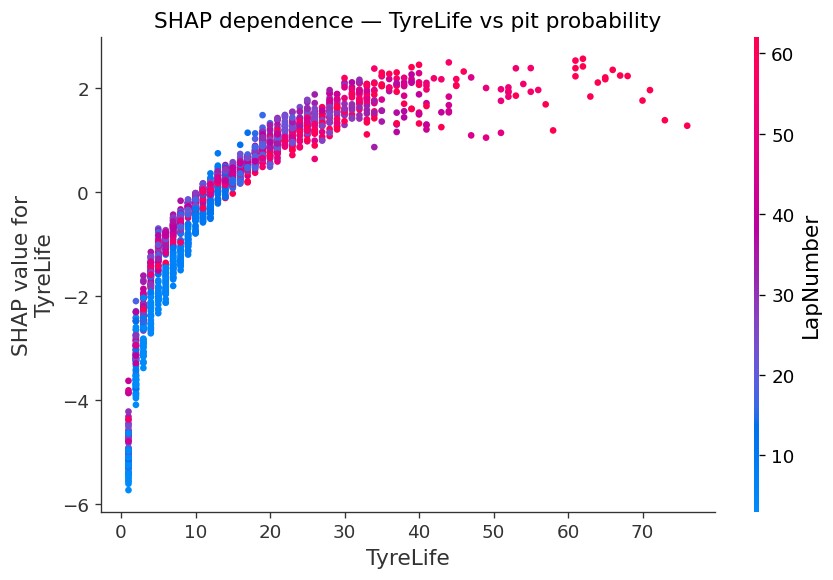

In [12]:
# SHAP dependence — TyreLife (expected top feature)
import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(final_model)
sv = explainer.shap_values(X_sample)

shap.dependence_plot('TyreLife', sv, X_sample,
                     feature_names=cfg.ALL_FEATURES, show=False)
plt.title('SHAP dependence — TyreLife vs pit probability', fontsize=13)
plt.tight_layout()
plt.savefig(cfg.FIG_DIR / 'shap_dependence_tyrelife.png', bbox_inches='tight')
plt.show()

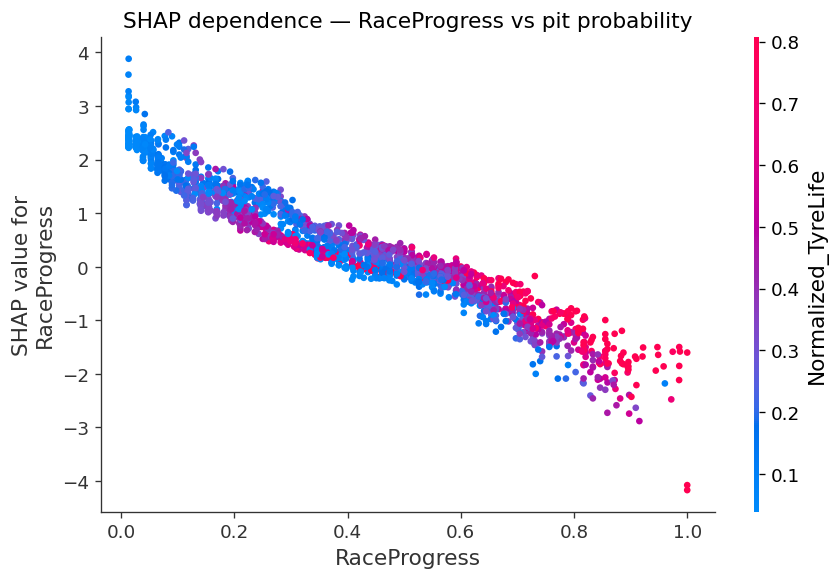

In [13]:
# SHAP dependence — RaceProgress
shap.dependence_plot('RaceProgress', sv, X_sample,
                     feature_names=cfg.ALL_FEATURES, show=False)
plt.title('SHAP dependence — RaceProgress vs pit probability', fontsize=13)
plt.tight_layout()
plt.savefig(cfg.FIG_DIR / 'shap_dependence_raceprogress.png', bbox_inches='tight')
plt.show()


> **Note: Please Run this cell only once. The test set (2025 data) must never be used for training or tuning.**

In [14]:
#Final Evaluation
test_probs = final_model.predict_proba(X_test_e)[:, 1]
test_preds = (test_probs >= final_thresh).astype(int)

test_metrics = get_metrics('FINAL — Test Set (2025)',
                            y_test_e, test_preds, test_probs)

print('\n' + '='*55)
print('  FINAL TEST RESULTS (2025 races)')
print('='*55)
for k, v in test_metrics.items():
    print(f'  {k:<12}: {v}')


  FINAL TEST RESULTS (2025 races)
  Model       : FINAL — Test Set (2025)
  Accuracy    : 0.7423
  Precision   : 0.5949
  Recall      : 0.7027
  F1          : 0.6444
  ROC-AUC     : 0.8169



  Final Model — Test Set (2025) — Classification Report
              precision    recall  f1-score   support

      No Pit       0.84      0.76      0.80     17236
         Pit       0.59      0.70      0.64      8575

    accuracy                           0.74     25811
   macro avg       0.72      0.73      0.72     25811
weighted avg       0.76      0.74      0.75     25811



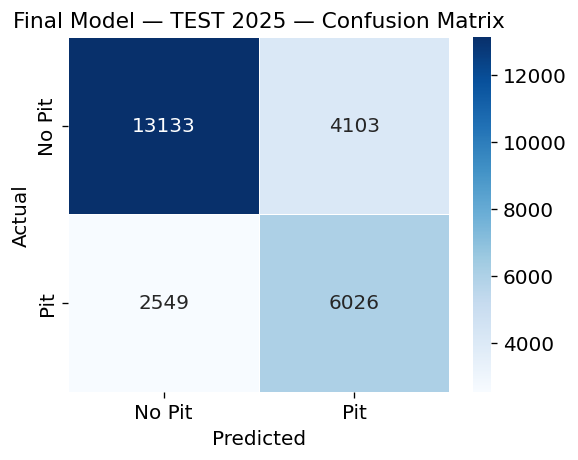

In [15]:
print_report('Final Model — Test Set (2025)', y_test_e, test_preds)
plot_cm(y_test_e, test_preds, 'Final Model — TEST 2025',
        fname='final_test_cm.png')

In [16]:
save_model(final_model, 'xgb_final')

final_summary = {
    'best_params'    : best_params,
    'final_threshold': final_thresh,
    'val_metrics'    : final_results,
    'test_metrics'   : test_metrics,
    'features_used'  : cfg.ALL_FEATURES,
}
(cfg.OUT_DIR / 'final_summary.json').write_text(
    json.dumps(final_summary, indent=2)
)
print('Final model and summary saved to outputs/')

[save_model] Saved → c:\Users\adity\OneDrive\Desktop\F1-Pitstop-Predictor\notebooks\..\outputs\models\xgb_final.joblib
Final model and summary saved to outputs/


## 9. Report Summary

### What the model learned
- **TyreLife** and **Normalized_TyreLife** dominate SHAP importance-confirms that tyre age is the strongest predictor.
- **RaceProgress** shows a bimodal SHAP effect - high impact at mid-race (typical 2-stop window).
- **LapsSinceLastPit** (engineered) is a top-5 feature- captures "overdue for a stop" urgency.
- **LapTime_Delta** has a smaller but consistent positive SHAP -slower laps slightly increase pit probability.

### What we'd do next
- Add safety car laps as a feature (currently missing from dataset)
- Include weather data (wet/damp track drastically changes strategy)
- Try a recurrent model (LSTM) — laps are sequential, temporal dependency could help
- Build per-team models — Red Bull and Mercedes pit strategy differs significantly

### Limitations
- No safety car or virtual safety car flag in dataset
- No real-time tyre temperature data
- 2025 test set represents only partial season data